# TradingAgents 变体实验回测

读取比例仓位、新闻情绪、做空和多轮辩论的数值信号，以及已导入的单 Agent 动作信号。各实验按同一股票和日期取原版及规则基线，使用同一套回测公式。原版完整窗口在 [analysis.ipynb](analysis.ipynb)。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from agents_single import validate_single_agent
from data import read_prices
from signals import load_decisions, validate_weights
from settings import load_config
from backtest import (
    build_baselines, save_baselines, load_baselines, load_original, original_frames,
    select_period, prepare_backtest, compare_positions, plot_backtest,
    monthly_strategy_returns, save_results,
)

ROOT = Path.cwd()


## 参数与实际信号日期

VARIANT_CSVS 选择要跑的变体。文件路径相对于 data/decisions，首层目录名是实验名。每个版本使用信号覆盖的时间窗口，在该窗口内与原版和规则基线比较。单 Agent 文件到位后自动加入对照。EXCLUDE_PERIODS=[] 使用完整区间。

In [2]:
cfg = load_config()
TICKERS = cfg["tickers"]
AGENT_CSV = ROOT / "data/decisions/ta-v0.6.0-deepseek-flash-market-news-fundamentals-main-2026jul-oct-v1.csv"
AGENT_NAME = "TradingAgents (3 analysts)"
VARIANT_CSVS = {
    "position/position_aug.csv": "Position sizing",
    "sentiment/sentiment_aug.csv": "News sentiment",
    "short/short_approval_aug.csv": "Short approval",
    "short/short_mapping.csv": "Short rating mapping",
    "debate/debate_r1_sep.csv": "Debate (1 round)",
    "debate/debate_r3_sep.csv": "Debate (3 rounds)",
}  # data/decisions/ 下的路径，首层目录名即实验名
SINGLE_AGENT_CSV = "single/single_agent.csv"
if (ROOT / "data/decisions" / SINGLE_AGENT_CSV).is_file():
    VARIANT_CSVS[SINGLE_AGENT_CSV] = "Single Agent"
if not VARIANT_CSVS:
    raise ValueError("请在 VARIANT_CSVS 中至少选择一个变体")
RETURN_TYPE = "simple"
NAV_MODE = "additive"  # 保留原净值口径；可改为 compound

# 特殊日期筛选：起止日均包含，可追加多段；设为 [] 恢复完整回测。
# 与区间相交的开盘到下一开盘收益会被排除，所有股票和策略使用同一筛选。
EXCLUDE_PERIODS = [("2026-07-30", "2026-08-03")] #("2026-07-30", "2026-08-03")

# 首日为种子信号，次一交易日开始成交；完整覆盖由后面的校验检查。
signal_input = pd.read_csv(AGENT_CSV, keep_default_na=False)
signal_dates = sorted(signal_input.information_cutoff.str[:10].unique())
seed_date = signal_dates[0]
backtest_start, backtest_end = signal_dates[1], signal_dates[-1]
periods = {"agent_period": (backtest_start, backtest_end)}
period_label = "Agent signal period"
if EXCLUDE_PERIODS:
    period_label += "\nExcluded: " + ", ".join(f"{a} to {b}" for a, b in EXCLUDE_PERIODS)
period_names = {"agent_period": period_label}
pd.DataFrame(periods, index=["start", "end"]).T


,start,end
agent_period,2026-07-01,2026-10-09


## 1. 读取行情
保留完整历史用于指标预热；开盘到下一开盘收益在合并信号时统一构造。


In [3]:
# 完整历史用于SMA/MACD预热，收益只在实际信号期间计算。
price_histories = {ticker: read_prices(ticker, cfg, backtest_end) for ticker in TICKERS}
pd.DataFrame([
    {"ticker": ticker, "first_date": prices.date.iloc[0],
     "last_date": prices.date.iloc[-1], "rows": len(prices)}
    for ticker, prices in price_histories.items()
])


,ticker,first_date,last_date,rows
0,AAPL,2023-01-03,2026-10-09,946
1,GOOGL,2023-01-03,2026-10-09,946
2,AMZN,2023-01-03,2026-10-09,946


## 2. 生成同期规则信号并保存CSV
Buy and Hold、SMA、MACD与Agent共用日期和种子日。先落盘，再读取回测。


In [4]:
baseline_tables = build_baselines(price_histories, cfg, backtest_start, backtest_end)


In [5]:
baseline_paths = save_baselines(baseline_tables, ROOT, backtest_start, backtest_end, cfg)
pd.Series(baseline_paths, name="signals_csv")


AAPL     /Users/Admin/Documents/hkust/course/BDT5018NLP...
GOOGL    /Users/Admin/Documents/hkust/course/BDT5018NLP...
AMZN     /Users/Admin/Documents/hkust/course/BDT5018NLP...
Name: signals_csv, dtype: object

## 3. 读取信号 CSV

原版、规则基线和单 Agent 读取 BUY／SELL／HOLD 动作。其余变体读取 ticker、signal_date、target_weight，空权重填 0。

In [6]:
decision_tables = load_baselines(baseline_paths, backtest_start, backtest_end)


In [7]:
strategy_names = {
    "buy_hold": "Buy and Hold",
    "sma": f"SMA Trend ({cfg['sma']['fast']}/{cfg['sma']['slow']})",
    "macd": f"MACD Trend ({cfg['macd']['fast']}/{cfg['macd']['slow']}/{cfg['macd']['signal']})",
}

decision_tables.update(load_original(AGENT_CSV, TICKERS, backtest_start, backtest_end))
strategy_names["agent"] = AGENT_NAME
variant_tables = {}
variant_paths = {}
for relative_path, label in VARIANT_CSVS.items():
    signal_path = Path(relative_path)
    if (signal_path.is_absolute() or len(signal_path.parts) < 2
            or ".." in signal_path.parts or signal_path.parts[0] == "original"):
        raise ValueError(f"请使用 data/decisions/ 下的实验子目录路径：{relative_path}")
    path = ROOT / "data/decisions" / signal_path
    strategy = path.stem
    if strategy in strategy_names:
        raise ValueError(f"重复策略名：{strategy}")
    strategy_names[strategy] = label
    variant_paths[strategy] = signal_path
    table = load_decisions(path)
    if table.empty or "ticker" not in table or not set(table.ticker).issubset(TICKERS):
        raise ValueError(f"{strategy} 缺少信号或含未知股票")
    for ticker, rows in table.groupby("ticker"):
        if signal_path.parts[0] == "single":
            variant_tables[ticker, strategy] = validate_single_agent(rows, ticker)
        else:
            variant_tables[ticker, strategy] = validate_weights(rows, ticker)
all_tables = decision_tables | variant_tables
pd.DataFrame([{"ticker": ticker, "strategy": strategy, "strategy_name": strategy_names[strategy],
               "decision_rows": len(rows)} for (ticker, strategy), rows in all_tables.items()])


,ticker,strategy,strategy_name,decision_rows
0,AAPL,buy_hold,Buy and Hold,72
1,AAPL,sma,SMA Trend (20/50),72
2,AAPL,macd,MACD Trend (12/26/9),72
3,GOOGL,buy_hold,Buy and Hold,72
4,GOOGL,sma,SMA Trend (20/50),72
5,GOOGL,macd,MACD Trend (12/26/9),72
6,AMZN,buy_hold,Buy and Hold,72
7,AMZN,sma,SMA Trend (20/50),72
8,AMZN,macd,MACD Trend (12/26/9),72
9,AAPL,agent,TradingAgents (3 analysts),72


## 4. 对齐下一开盘与收益区间

目标权重在这里截断到 [-1, 1]。短样本按已有信号覆盖的成交日至最终估值日单独比较，同期原版和规则基线重新从净值 1、仓位 0 开始计费。

In [8]:
base_frames = original_frames(price_histories, decision_tables, backtest_start, backtest_end, RETURN_TYPE)
position_tables = {}
comparison_periods = dict(periods)
for (ticker, strategy), rows in variant_tables.items():
    prices = price_histories[ticker]
    if "target_weight" in rows:
        days = prices.date.tolist()
        first = days.index(rows.signal_date.iloc[0]) + 1
        last = min(days.index(rows.signal_date.iloc[-1]) + 2, len(days) - 1)
        start, end = days[first], days[last]
    else:
        # 动作信号包含种子日和末日，末日用于确定最后一个估值开盘。
        start, end = rows.session.iloc[1], rows.session.iloc[-1]
    if not backtest_start <= start < end <= backtest_end:
        raise ValueError(f"{ticker} / {strategy} 不在原版可比较区间内")
    period = ("agent_period" if (start, end) == (backtest_start, backtest_end)
              else f"{start}_to_{end}")
    comparison_periods[period] = (start, end)
    period_names.setdefault(period, "Matched signal period")
    matched_prices = prices.loc[prices.date.between(start, end)]
    position_tables[ticker, period, strategy] = prepare_backtest(
        matched_prices, rows, return_type=RETURN_TYPE)
    for name in ("agent", "buy_hold", "sma", "macd"):
        key = (ticker, period, name)
        if key not in position_tables:
            position_tables[key] = select_period(base_frames[ticker, name], start, end)

pd.concat({key: frame[["open", "signal", "position", "pct"]].head(3)
           for key, frame in position_tables.items()}, names=["ticker", "period", "strategy"])

open  \
ticker period                   strategy      DateTime                                
AAPL   2026-08-03_to_2026-09-01 position_aug  2026-08-03 09:30:00-04:00  309.579987   
                                              2026-08-04 09:30:00-04:00  302.730011   
                                              2026-08-05 09:30:00-04:00  309.359985   
                                agent         2026-08-03 09:30:00-04:00  309.579987   
                                              2026-08-04 09:30:00-04:00  302.730011   
...                                                                             ...   
       2026-09-01_to_2026-10-01 macd          2026-09-02 09:30:00-04:00  326.869995   
                                              2026-09-03 09:30:00-04:00  324.869995   
                                debate_r3_sep 2026-09-01 09:30:00-04:00  316.980011   
                                              2026-09-02 09:30:00-04:00  326.869995   
                                              2026-09-03 09:30:00-04:00  324.869995   

                                                                         signal  \
ticker period                   strategy      DateTime                            
AAPL   2026-08-03_to_2026-09-01 position_aug  2026-08-03 09:30:00-04:00     0.0   
                                              2026-08-04 09:30:00-04:00     0.0   
                                              2026-08-05 09:30:00-04:00     0.0   
                                agent         2026-08-03 09:30:00-04:00     0.0   
                                              2026-08-04 09:30:00-04:00     1.0   
...                                                                         ...   
       2026-09-01_to_2026-10-01 macd          2026-09-02 09:30:00-04:00     1.0   
                                              2026-09-03 09:30:00-04:00     1.0   
                                debate_r3_sep 2026-09-01 09:30:00-04:00     0.0   
                                              2026-09-02 09:30:00-04:00     0.0   
                                              2026-09-03 09:30:00-04:00     1.0   

                                                                         position  \
ticker period                   strategy      DateTime                              
AAPL   2026-08-03_to_2026-09-01 position_aug  2026-08-03 09:30:00-04:00       0.0   
                                              2026-08-04 09:30:00-04:00       0.0   
                                              2026-08-05 09:30:00-04:00       0.0   
                                agent         2026-08-03 09:30:00-04:00       0.0   
                                              2026-08-04 09:30:00-04:00       1.0   
...                                                                           ...   
       2026-09-01_to_2026-10-01 macd          2026-09-02 09:30:00-04:00       1.0   
                                              2026-09-03 09:30:00-04:00       1.0   
                                debate_r3_sep 2026-09-01 09:30:00-04:00       0.0   
                                              2026-09-02 09:30:00-04:00       0.0   
                                              2026-09-03 09:30:00-04:00       1.0   

                                                                              pct  
ticker period                   strategy      DateTime                             
AAPL   2026-08-03_to_2026-09-01 position_aug  2026-08-03 09:30:00-04:00 -0.022127  
                                              2026-08-04 09:30:00-04:00  0.021901  
                                              2026-08-05 09:30:00-04:00  0.016098  
                                agent         2026-08-03 09:30:00-04:00 -0.022127  
                                              2026-08-04 09:30:00-04:00  0.021901  
...                                                                           ...  
       2026-09-01_to_2026-10-01 macd          2026-09-02 09:30:00-04:00 -0.006119  
     

## 统一回测口径

两本 Notebook 从 backtest.py 导入同一套函数。仓位按下一开盘对齐，期收益为仓位乘资产收益，扣除相邻仓位差绝对值乘费用。加法净值从 1 开始累计；筛选在计算完整收益和换手之后执行。

## 同期策略比较
按股票比较Agent与三条规则基线的收益、Sharpe、回撤与换手。


In [9]:
fee = (cfg["commission_bps"] + cfg["slippage_bps"]) / 10000
backtests, metrics_table = compare_positions(
    position_tables, strategy_names, cfg, fee, RETURN_TYPE, NAV_MODE, EXCLUDE_PERIODS)
metrics_table


strategy_name  \
ticker period                   strategy                                         
AAPL   2026-08-03_to_2026-09-01 position_aug                   Position sizing   
                                agent               TradingAgents (3 analysts)   
                                buy_hold                          Buy and Hold   
                                sma                          SMA Trend (20/50)   
                                macd                      MACD Trend (12/26/9)   
                                sentiment_aug                   News sentiment   
                                short_approval_aug              Short approval   
       agent_period             short_mapping             Short rating mapping   
                                agent               TradingAgents (3 analysts)   
                                buy_hold                          Buy and Hold   
                                sma                          SMA Trend (20/50)   
                                macd                      MACD Trend (12/26/9)   
AMZN   agent_period             short_mapping             Short rating mapping   
                                agent               TradingAgents (3 analysts)   
                                buy_hold                          Buy and Hold   
                                sma                          SMA Trend (20/50)   
                                macd                      MACD Trend (12/26/9)   
GOOGL  agent_period             short_mapping             Short rating mapping   
                                agent               TradingAgents (3 analysts)   
                                buy_hold                          Buy and Hold   
                                sma                          SMA Trend (20/50)   
                                macd                      MACD Trend (12/26/9)   
AAPL   2026-09-01_to_2026-10-01 debate_r1_sep                 Debate (1 round)   
                                agent               TradingAgents (3 analysts)   
                                buy_hold                          Buy and Hold   
                                sma                          SMA Trend (20/50)   
                                macd                      MACD Trend (12/26/9)   
                                debate_r3_sep                Debate (3 rounds)   

                                                    cumulative_return  \
ticker period                   strategy                                
AAPL   2026-08-03_to_2026-09-01 position_aug                -0.003934   
                                agent                        0.028524   
                                buy_hold                     0.048191   
                                sma                          0.026423   
                                macd                         0.019768   
                                sentiment_aug               -0.020809   
                                short_approval_aug           0.028524   
       agent_period             short_mapping                0.206671   
                                agent                        0.227305   
                                buy_hold                     0.245939   
                                sma                          0.157616   
                                macd                         0.166197   
AMZN   agent_period             short_mapping                0.160758   
                                agent                        0.025229   
                                buy_hold                    -0.110301   
                                sma                         -0.105923   
                                macd                        -0.073899   
GOOGL  agent_period             short_mapping               -0.095032   
                                agent                       -0.097178   
                                buy_hold                    -0.099325  

## 按实验绘制净值与回撤

每个实验单独显示，与原版和规则基线使用相同股票、收益日期和费用。不同评价区间分别画图。

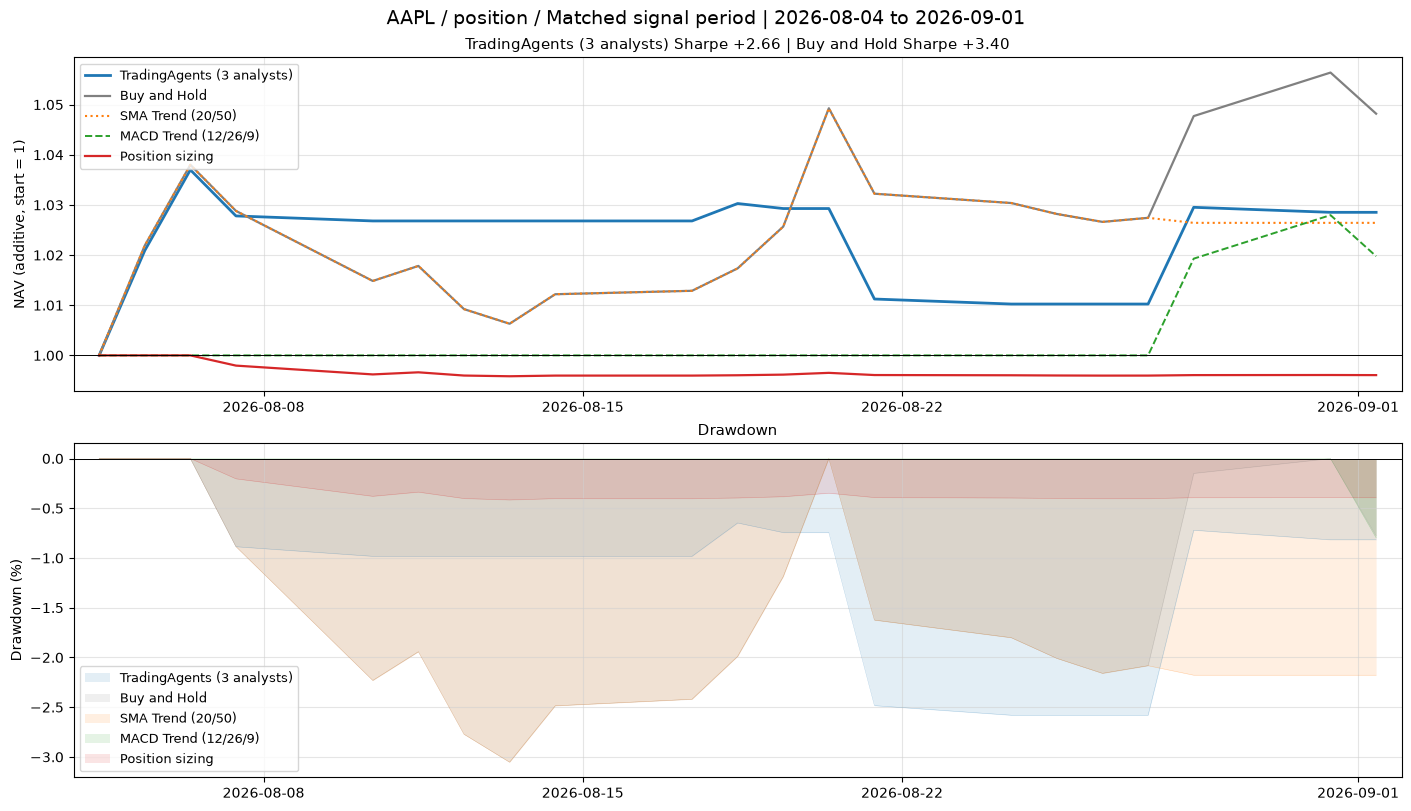

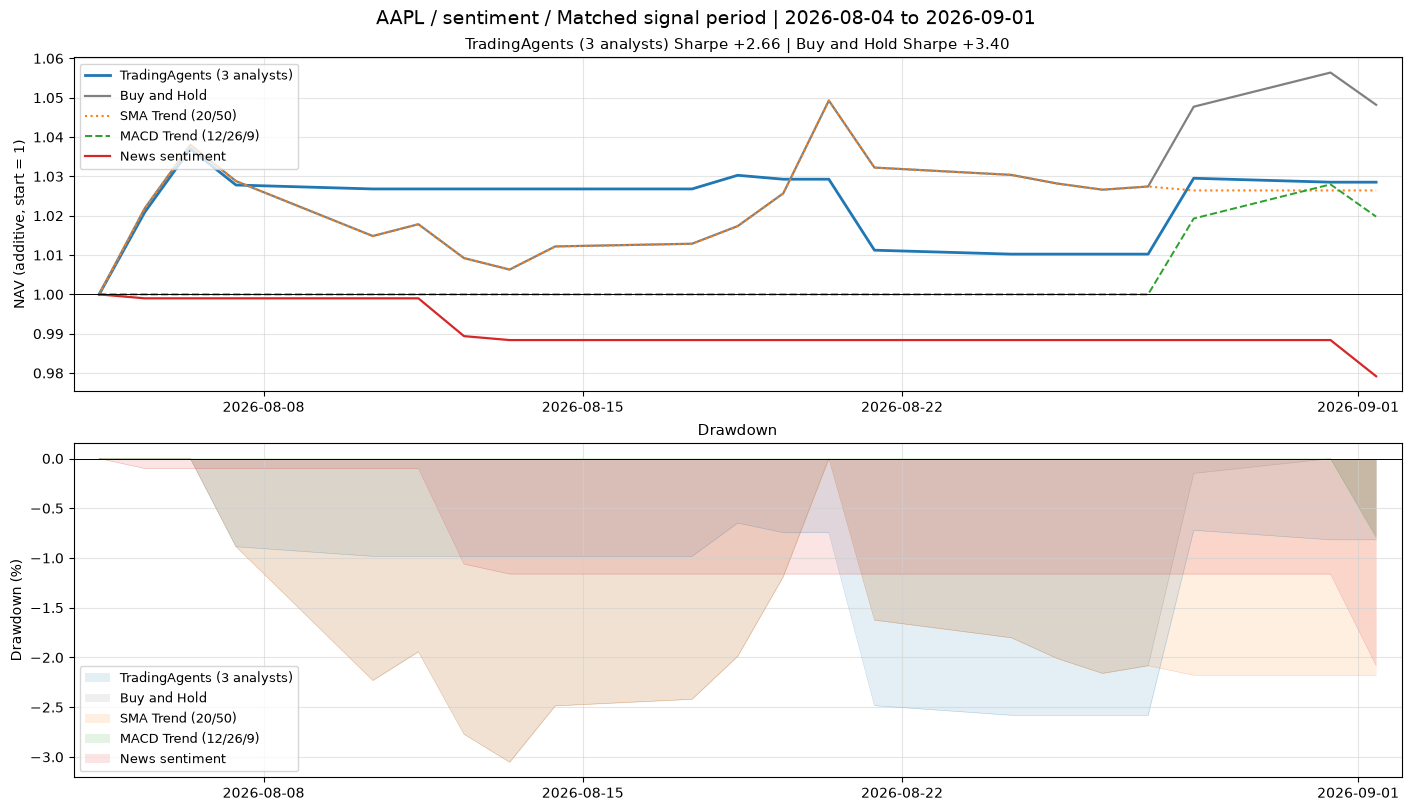

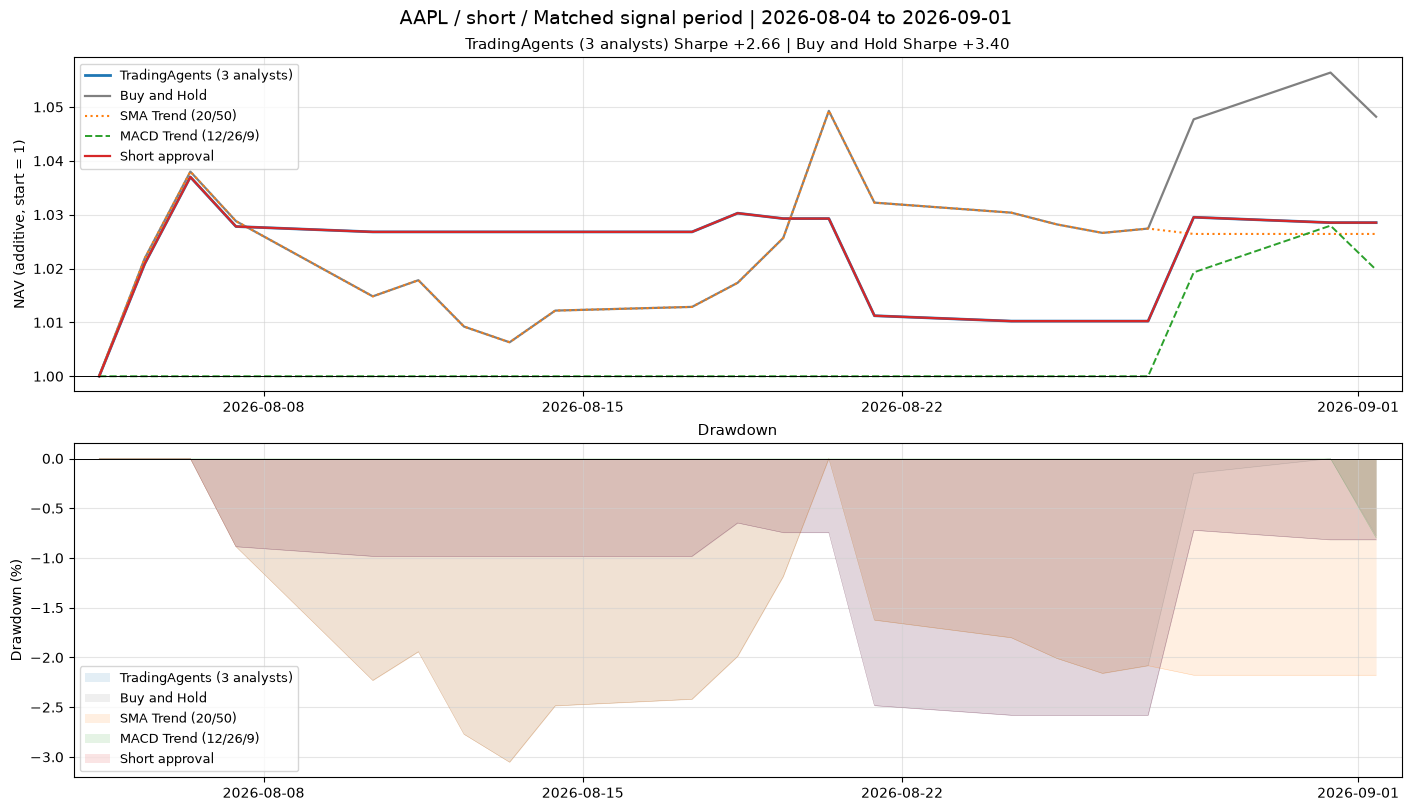

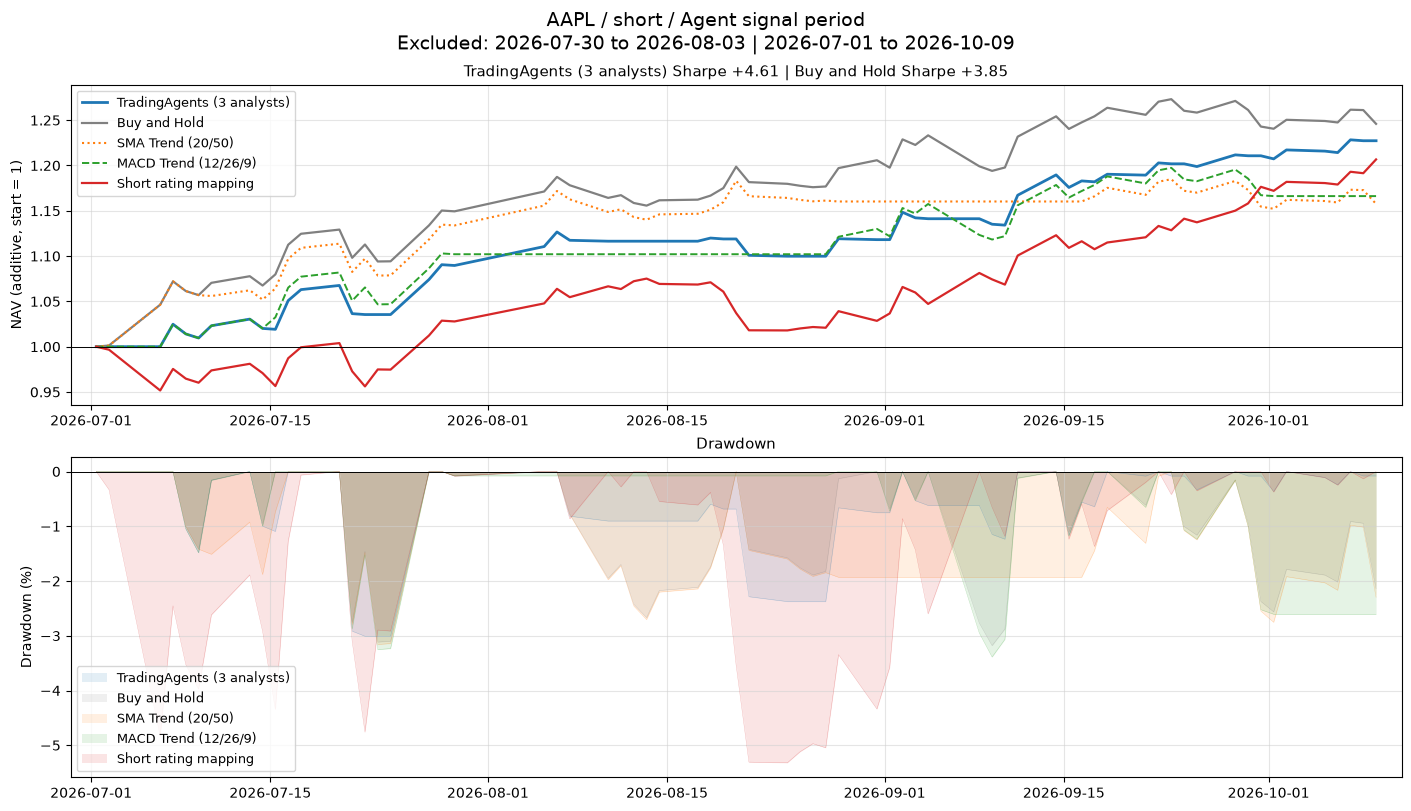

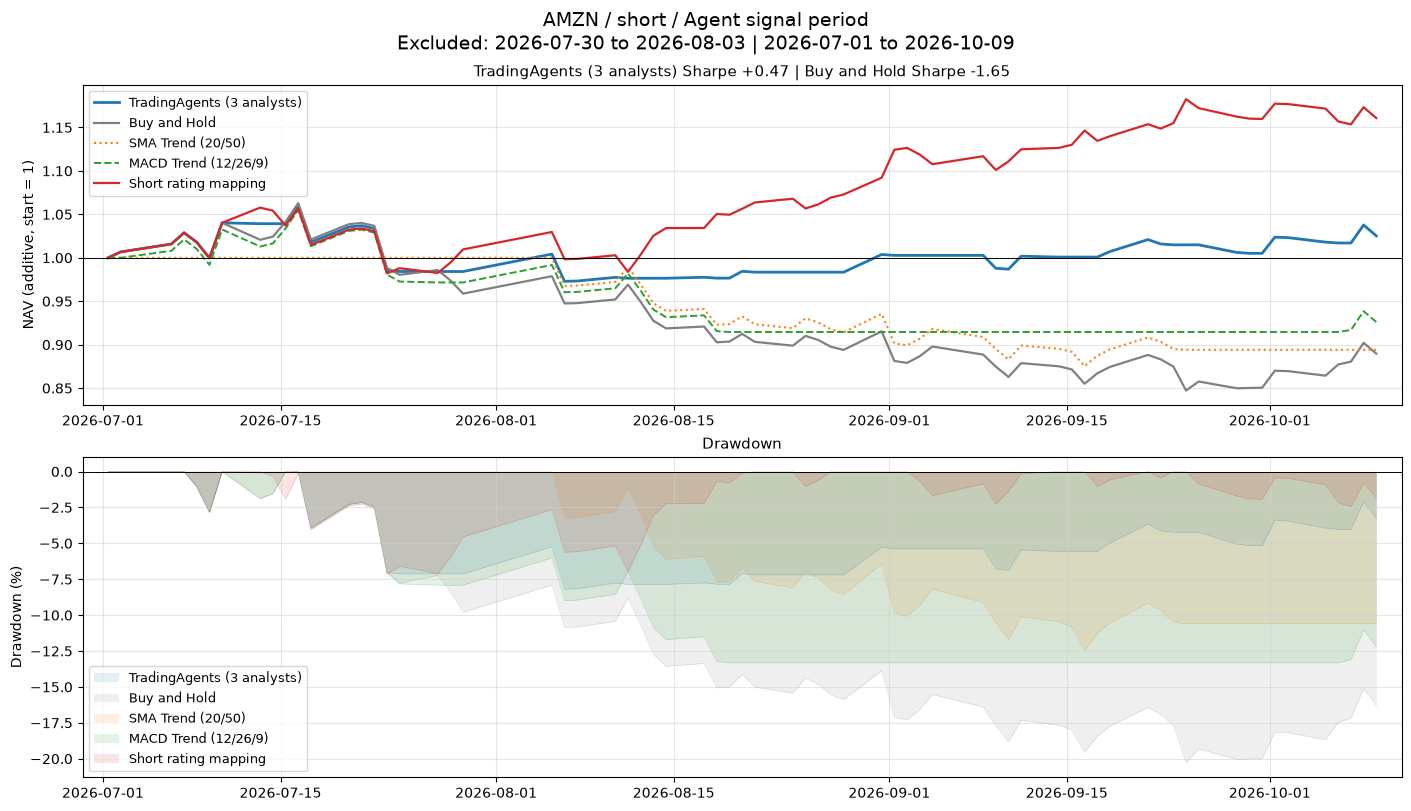

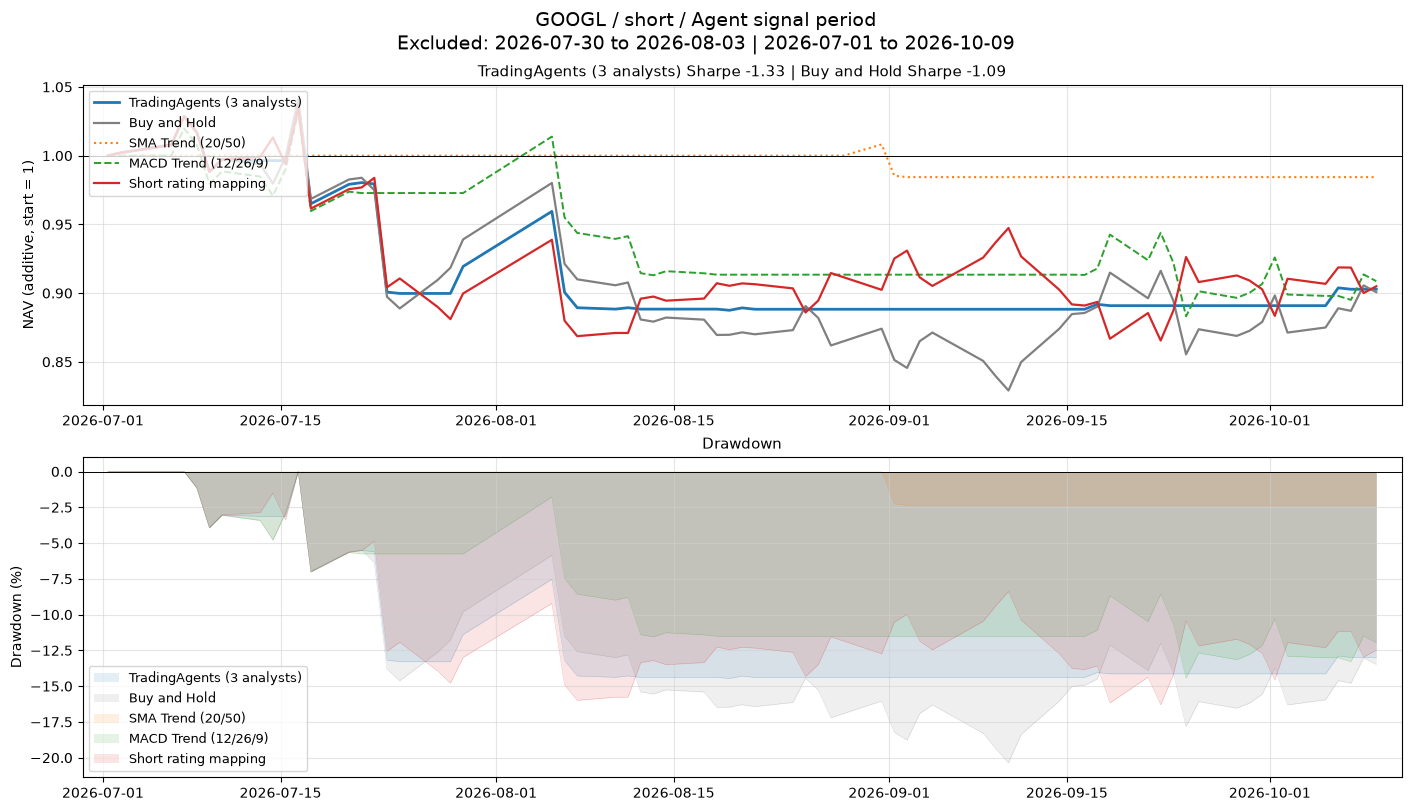

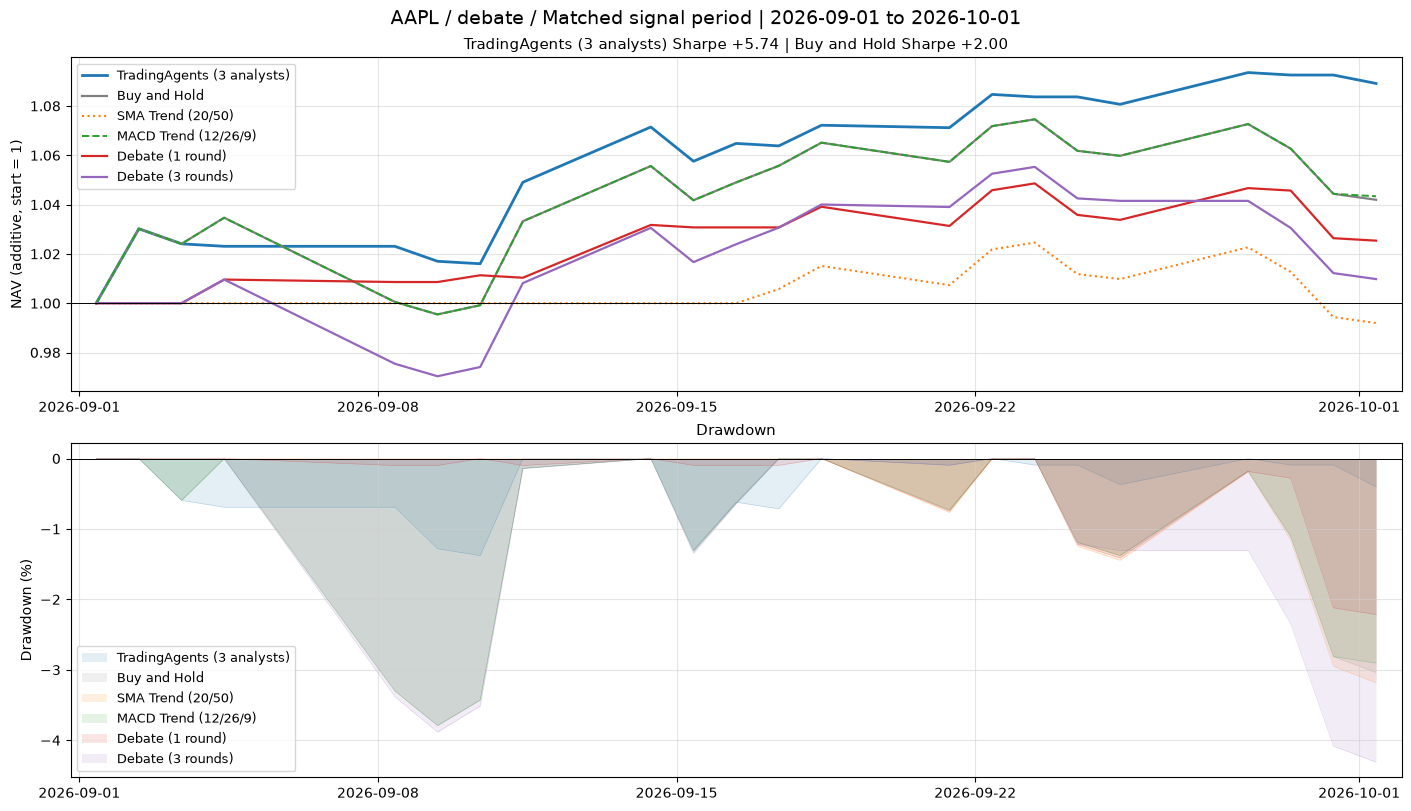

In [10]:
# 同一批回测共用收益计算，只按实验归档、绘图。
baseline_names = ("agent", "buy_hold", "sma", "macd")
experiment_cases = {}
for (ticker, period, strategy), frame in backtests.items():
    if strategy in variant_paths:
        experiment = variant_paths[strategy].parts[0]
        cases = experiment_cases.setdefault(experiment, {})
        frames = cases.setdefault((ticker, period), {
            name: backtests[ticker, period, name] for name in baseline_names
        })
        frames[strategy] = frame

figures = {}
for experiment, cases in experiment_cases.items():
    for (ticker, period), frames in cases.items():
        metrics = metrics_table.xs((ticker, period), level=("ticker", "period"))
        metrics = metrics.loc[list(frames)]
        fig, curves = plot_backtest(frames, strategy_names, metrics,
                                   f"{ticker} / {experiment} / {period_names[period]}",
                                   nav_mode=NAV_MODE)
        figures[experiment, ticker, period] = fig
        plt.show()
        plt.close(fig)


## 月收益与按实验导出

回测输出保存在 `results/<实验>/full/` 或 `results/<实验>/filtered/`。每组包括指标、月收益、逐期收益与换手、净值和回撤图以及本次运行参数。

In [11]:
monthly_returns = monthly_strategy_returns(backtests, NAV_MODE)
monthly_returns.to_frame()


return
ticker period                   strategy      month                              
AAPL   2026-08-03_to_2026-09-01 position_aug  2026-08-31 00:00:00-04:00 -0.003913
                                              2026-09-30 00:00:00-04:00 -0.000020
                                agent         2026-08-31 00:00:00-04:00  0.028524
                                              2026-09-30 00:00:00-04:00  0.000000
                                buy_hold      2026-08-31 00:00:00-04:00  0.056389
...                                                                           ...
       2026-09-01_to_2026-10-01 sma           2026-10-31 00:00:00-04:00 -0.002418
                                macd          2026-09-30 00:00:00-04:00  0.044372
                                              2026-10-31 00:00:00-04:00 -0.001000
                                debate_r3_sep 2026-09-30 00:00:00-04:00  0.012207
                                              2026-10-31 00:00:00-04:00 -0.002418

[86 rows x 1 columns]

In [12]:
mode = "filtered" if EXCLUDE_PERIODS else "full"
output_dirs = {}

for experiment, cases in experiment_cases.items():
    output_dir = ROOT / "results" / experiment / mode
    strategies = {strategy: strategy_names[strategy]
                  for frames in cases.values() for strategy in frames}
    record = {
        "experiment": experiment, "tickers": sorted({ticker for ticker, _ in cases}),
        "periods": {period: comparison_periods[period] for _, period in cases},
        "strategies": strategies,
        "agent_csv": str(AGENT_CSV.relative_to(ROOT)),
        "baseline_csvs": {ticker: str(baseline_paths[ticker].relative_to(ROOT))
                          for ticker, _ in cases},
        "variant_csvs": [str(path) for path in variant_paths.values() if path.parts[0] == experiment],
        "return_type": RETURN_TYPE, "nav_mode": NAV_MODE, "fee": fee, "exclude_periods": EXCLUDE_PERIODS,
    }
    case_figures = {(ticker, period): figures[experiment, ticker, period] for ticker, period in cases}
    save_results(output_dir, cases, metrics_table, monthly_returns, case_figures, record)
    output_dirs[experiment] = output_dir

pd.Series(output_dirs, name="回测输出目录")


position     /Users/Admin/Documents/hkust/course/BDT5018NLP...
sentiment    /Users/Admin/Documents/hkust/course/BDT5018NLP...
short        /Users/Admin/Documents/hkust/course/BDT5018NLP...
debate       /Users/Admin/Documents/hkust/course/BDT5018NLP...
Name: 回测输出目录, dtype: object